# Uber NYC Pickup Demand & Geospatial Mobility Analysis

## Project Overview
* This project presents an end-to-end Exploratory Data Analysis (EDA) on **3,506,191 Uber trip records** in New York City spanning **April to August 2014**. The study evaluates temporal demand cycles (hourly, daily, and monthly), geographic pickup latitude shifts between commercial and residential zones, and operational workload distribution across Uber's five dispatch bases.
* **Environment & Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly Express, OS.
* **Dataset Scope:** 5 monthly raw CSV files (`apr14` through `aug14`) consolidated into 3,506,191 records across 4 initial attributes: pickup timestamp (`Date/Time`), latitude (`Lat`), longitude (`Lon`), and TLC dispatch base code (`Base`).

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os


In [ ]:
files = os.listdir("/content/drive/MyDrive/Uber")
files

['uber-raw-data-apr14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv']

In [ ]:
path = "/content/drive/MyDrive/Uber"
final = pd.DataFrame()
for file in files:
  df = pd.read_csv(path + "/" + file)
  final = pd.concat([df, final])

print(final)

                 Date/Time      Lat      Lon    Base
0         7/1/2014 0:03:00  40.7586 -73.9706  B02512
1         7/1/2014 0:05:00  40.7605 -73.9994  B02512
2         7/1/2014 0:06:00  40.7320 -73.9999  B02512
3         7/1/2014 0:09:00  40.7635 -73.9793  B02512
4         7/1/2014 0:20:00  40.7204 -74.0047  B02512
...                    ...      ...      ...     ...
564511  4/30/2014 23:22:00  40.7640 -73.9744  B02764
564512  4/30/2014 23:26:00  40.7629 -73.9672  B02764
564513  4/30/2014 23:31:00  40.7443 -73.9889  B02764
564514  4/30/2014 23:32:00  40.6756 -73.9405  B02764
564515  4/30/2014 23:48:00  40.6880 -73.9608  B02764

[3506191 rows x 4 columns]


In [ ]:
final.shape

(3506191, 4)

In [ ]:
final.info()



<class 'pandas.core.frame.DataFrame'>
Index: 3506191 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 133.8+ MB


In [ ]:
df = final.copy()
df.head()

,Date/Time,Lat,Lon,Base
0,7/1/2014 0:03:00,40.7586,-73.9706,B02512
1,7/1/2014 0:05:00,40.7605,-73.9994,B02512
2,7/1/2014 0:06:00,40.7320,-73.9999,B02512
3,7/1/2014 0:09:00,40.7635,-73.9793,B02512
4,7/1/2014 0:20:00,40.7204,-74.0047,B02512


In [ ]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"], format = "%m/%d/%Y %H:%M:%S")
df.info()
print(df)

<class 'pandas.core.frame.DataFrame'>
Index: 3506191 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype         
---  ------     -----         
 0   Date/Time  datetime64[ns]
 1   Lat        float64       
 2   Lon        float64       
 3   Base       object        
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 133.8+ MB
                 Date/Time      Lat      Lon    Base
0      2014-07-01 00:03:00  40.7586 -73.9706  B02512
1      2014-07-01 00:05:00  40.7605 -73.9994  B02512
2      2014-07-01 00:06:00  40.7320 -73.9999  B02512
3      2014-07-01 00:09:00  40.7635 -73.9793  B02512
4      2014-07-01 00:20:00  40.7204 -74.0047  B02512
...                    ...      ...      ...     ...
564511 2014-04-30 23:22:00  40.7640 -73.9744  B02764
564512 2014-04-30 23:26:00  40.7629 -73.9672  B02764
564513 2014-04-30 23:31:00  40.7443 -73.9889  B02764
564514 2014-04-30 23:32:00  40.6756 -73.9405  B02764
564515 2014-04-30 23:48:00  40.6880 -73.9608  B02764

In [ ]:
df["weekday"] = df["Date/Time"].dt.day_name()
df["day"] = df["Date/Time"].dt.day
df["minute"] = df["Date/Time"].dt.minute
df["month"] = df["Date/Time"].dt.month
df["hour"] = df["Date/Time"].dt.hour

df

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
0,2014-07-01 00:03:00,40.7586,-73.9706,B02512,Tuesday,1,3,7,0
1,2014-07-01 00:05:00,40.7605,-73.9994,B02512,Tuesday,1,5,7,0
2,2014-07-01 00:06:00,40.7320,-73.9999,B02512,Tuesday,1,6,7,0
3,2014-07-01 00:09:00,40.7635,-73.9793,B02512,Tuesday,1,9,7,0
4,2014-07-01 00:20:00,40.7204,-74.0047,B02512,Tuesday,1,20,7,0
...,...,...,...,...,...,...,...,...,...
564511,2014-04-30 23:22:00,40.7640,-73.9744,B02764,Wednesday,30,22,4,23
564512,2014-04-30 23:26:00,40.7629,-73.9672,B02764,Wednesday,30,26,4,23
564513,2014-04-30 23:31:00,40.7443,-73.9889,B02764,Wednesday,30,31,4,23
564514,2014-04-30 23:32:00,40.6756,-73.9405,B02764,Wednesday,30,32,4,23


## Data Consolidation, Cleaning & Feature Engineering
* **Multi-File Consolidation:** Utilized Python's `os.listdir()` and `pd.concat()` to merge five monthly datasets (April–August 2014) into a single unified DataFrame containing **3,506,191 rows** and **4 columns**.
* **Datetime Standardization:** Converted the raw `Date/Time` string attribute into `datetime64[ns]` format via `pd.to_datetime()` to enable accurate time-series slicing.
* **Temporal Feature Engineering:** Extracted five granular time features—`weekday`, `day`, `minute`, `month`, and `hour`—expanding the dataset to **9 columns** for multi-dimensional demand analysis.

In [ ]:
!pip install plotly-express

In [ ]:
print(df["weekday"].value_counts())
print(df["weekday"].value_counts().index)
print(df["weekday"].value_counts().values)

weekday
Thursday     601869
Friday       580759
Wednesday    561115
Tuesday      500559
Saturday     484057
Monday       404184
Sunday       373648
Name: count, dtype: int64
Index(['Thursday', 'Friday', 'Wednesday', 'Tuesday', 'Saturday', 'Monday',
       'Sunday'],
      dtype='object', name='weekday')
[601869 580759 561115 500559 484057 404184 373648]


In [ ]:
import plotly_express as px
px.bar(x = df["weekday"].value_counts().index,
       y = df["weekday"].value_counts().values)

## Exploratory Data Analysis & Key Insights

### A. Trip Demand by Day of the Week
Aggregating total trip volume across weekdays revealed strong mid-to-late workweek commuter and leisure demand:
* **Thursday (`601,869` trips / `17.17%`)** and **Friday (`580,759` trips / `16.56%`)** recorded the highest ride volumes, driven by combined business commuting and evening social outings.
* **Mid-Week Stability:** **Wednesday (`561,115` trips / `16.00%`)** and **Tuesday (`500,559` trips / `14.28%`)** maintained high baseline ridership.
* **Weekend & Early-Week Contraction:** Ridership tapered off on **Saturday (`484,057` trips / `13.81%`)**, **Monday (`404,184` trips / `11.53%`)**, and reached its lowest point on **Sunday (`373,648` trips / `10.66%`)**.

(array([165986.,  80053., 173583., 417232., 248396., 282094., 637405.,
        512456., 445469., 543517.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ]),
 <BarContainer object of 10 artists>)

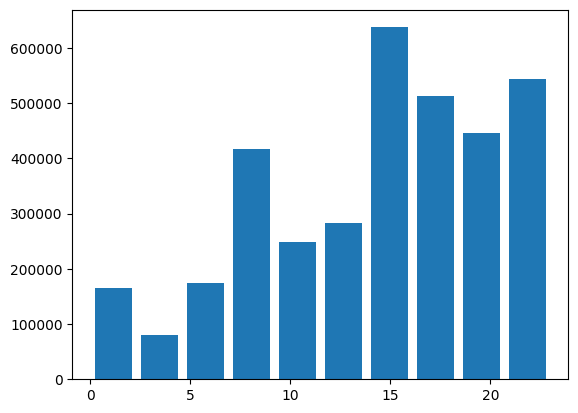

In [ ]:
plt.hist(df["hour"], rwidth = 0.8)

### B. Hourly Demand & Rush Hour Patterns
Evaluating trip distribution across the 24-hour cycle highlighted a clear bimodal commuting pattern:
* **Morning Commute Surge (07:00 – 09:00):** Pickup activity climbed sharply during morning office hours, exceeding **417,000 trips** in the morning rush window.
* **Afternoon & Evening Peak (14:00 – 23:00):** Demand surged to its daily maximum during the late afternoon commute (**637,405 trips** in the 14:00–16:00 window and **512,456 trips** in 16:00–18:30) and sustained high evening volume (**543,517 trips** between 20:30 and 23:00).
* **Overnight Lull (02:00 – 05:00):** Early morning hours experienced the lowest operational demand, dropping to **80,053 trips** in the 02:30–04:30 window.

In [ ]:
print(df["month"].unique())


[7 8 5 6 4]


In [ ]:
for i, month in enumerate(df["month"].unique()):
  print(f"{i + 1}. {month}")

1. 7
2. 8
3. 5
4. 6
5. 4


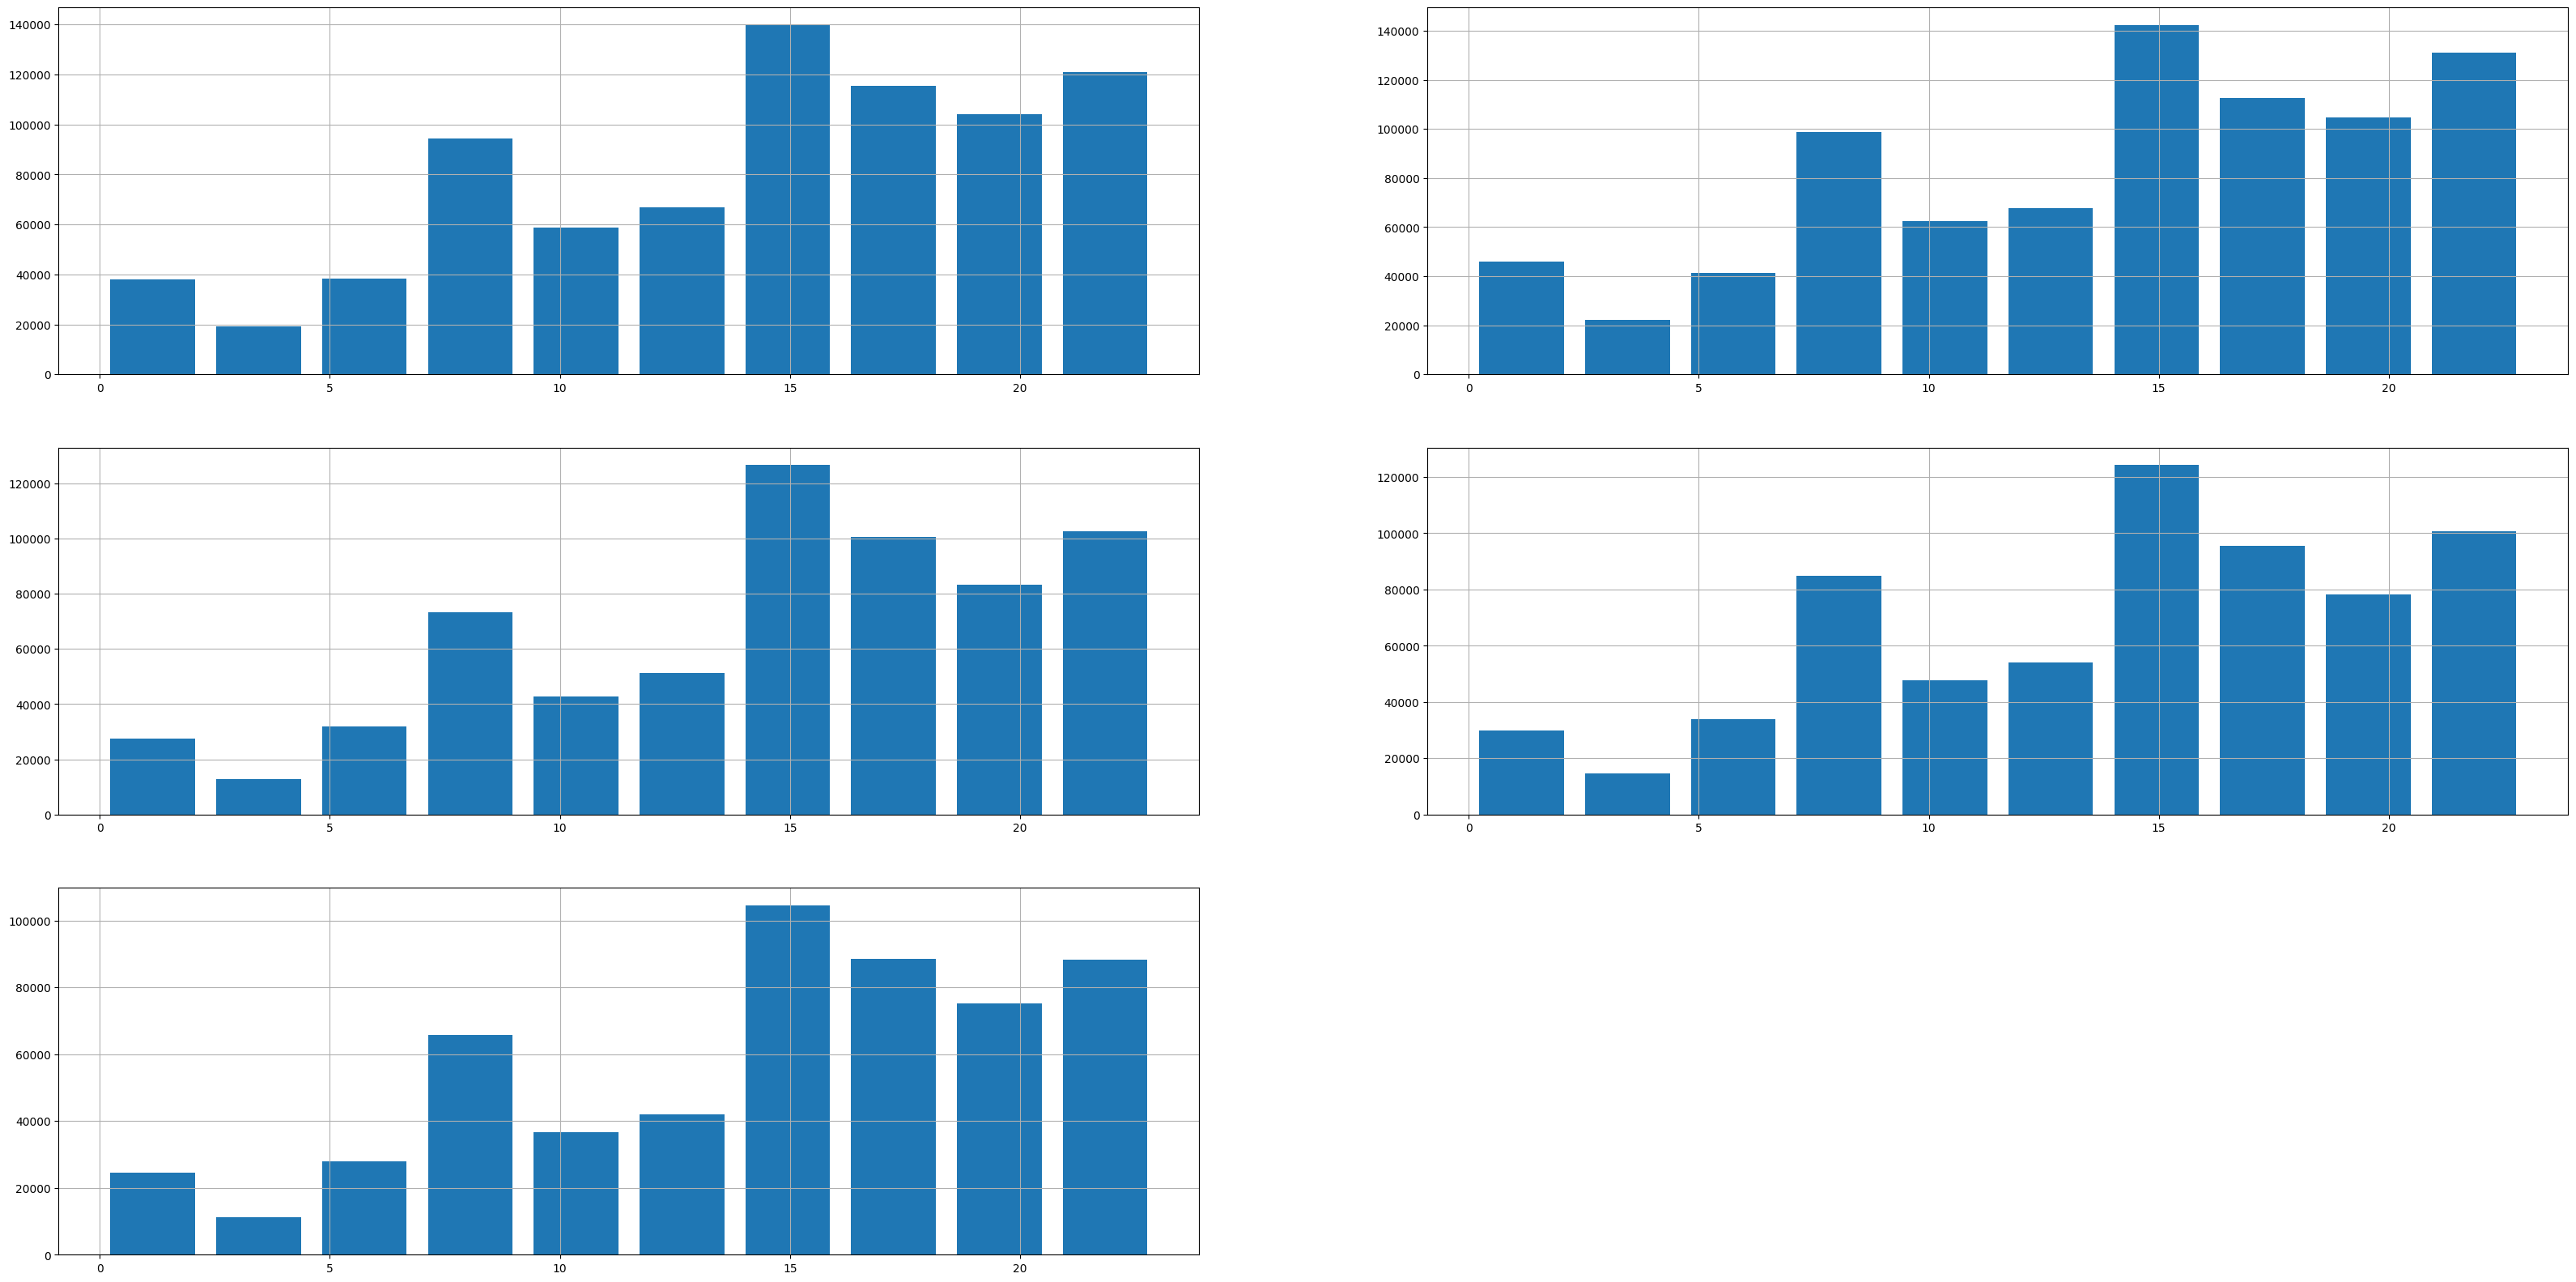

In [ ]:
plt.figure(figsize=(40, 20))
for i, month in enumerate(df["month"].unique()):
  plt.subplot(3, 2, i + 1)
  df[df["month"] == month]["hour"].hist(rwidth = 0.8)

In [ ]:
lama = df.groupby("month")["hour"].count()

px.bar(x = lama.index, y = lama.values)

(array([107469., 114370., 110352., 102563., 104735.,  99366., 113369.,
        115624., 120575., 116590., 112421., 121066., 113687., 112026.,
        124272., 122829., 116993., 111045., 112071., 105315., 112492.,
        118640., 125716., 112868., 114464., 115901., 106184., 111501.,
        119885., 133729.,  78073.]),
 array([ 1.        ,  1.96774194,  2.93548387,  3.90322581,  4.87096774,
         5.83870968,  6.80645161,  7.77419355,  8.74193548,  9.70967742,
        10.67741935, 11.64516129, 12.61290323, 13.58064516, 14.5483871 ,
        15.51612903, 16.48387097, 17.4516129 , 18.41935484, 19.38709677,
        20.35483871, 21.32258065, 22.29032258, 23.25806452, 24.22580645,
        25.19354839, 26.16129032, 27.12903226, 28.09677419, 29.06451613,
        30.03225806, 31.        ]),
 <BarContainer object of 31 artists>)

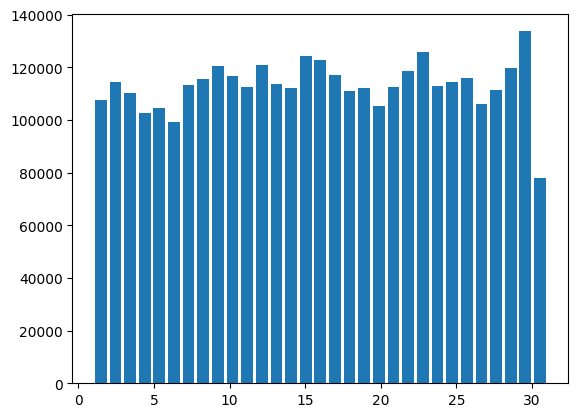

In [ ]:
plt.hist(df["day"], bins = 31, rwidth = 0.8)

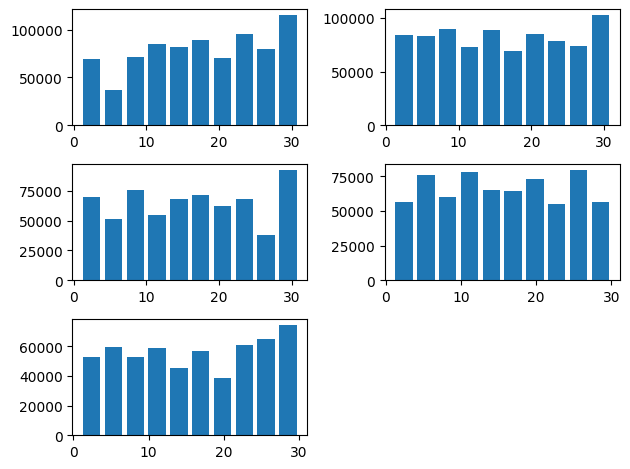

In [ ]:
for i, month in enumerate(df["month"].unique(), 1):
  plt.subplot(3, 2, i)
  df_out = df[df["month"] == month]
  plt.hist(df_out["day"], rwidth = 0.8)
  plt.tight_layout()


### C. Monthly Growth & Intra-Month Calendar Patterns
Tracking monthly trip totals (`month` 4 to 8) alongside day-of-month distributions (`day` 1 to 31) demonstrated rapid platform expansion:
* **Consistent Month-over-Month Growth:** Total monthly pickups grew steadily every single month from **April (`564,516` trips)** through **May (~652k)**, **June (~663k)**, and **July (~796k)**, peaking in **August (~829k trips)**—an overall expansion of **~47%** across the five-month period.
* **Day-of-Month Distribution:** Daily trip volume remained consistent throughout the month (~100k–125k trips per calendar day), peaking on **Day 30 (`133,729` trips)**. The sharp dip on **Day 31 (`78,073` trips)** reflects calendar structure, as only three of the five observed months (May, July, and August) contain 31 days.

<Axes: xlabel='hour', ylabel='Lat'>

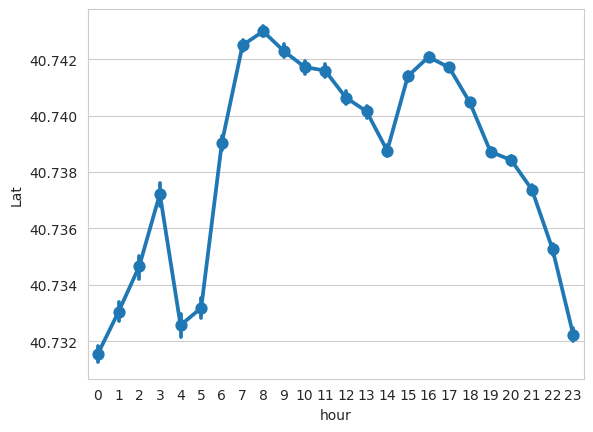

In [ ]:
sns.set_style(style="whitegrid")
sns.pointplot(x="hour", y="Lat", data = df)


<Axes: xlabel='hour', ylabel='Lat'>

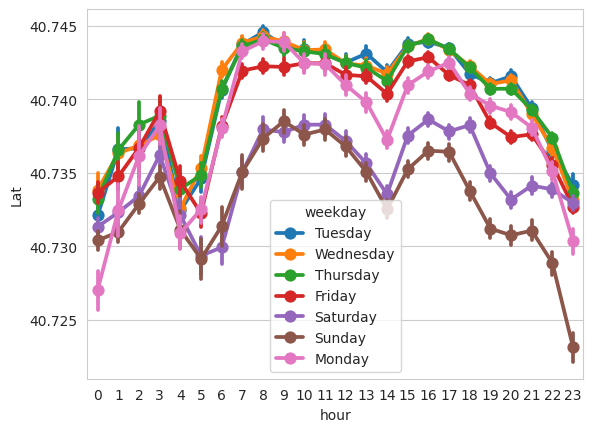

In [ ]:
sns.pointplot(x = "hour", y = "Lat", hue = "weekday", data = df)

### D. Geospatial Latitude Shifts by Hour & Day of Week
Analyzing mean pickup latitude (`Lat`) across hours and weekdays uncovered distinct geographic movement across New York City:
* **Daytime Midtown Concentration (07:00 – 18:00):** Average pickup latitude rose sharply during business hours (peaking at **~40.743–40.745**), indicating heavy trip concentration in Midtown Manhattan commercial and office districts.
* **Late-Night & Weekend Downtown Shift:** Between **22:00 and 05:00**—and consistently throughout **Saturday and Sunday**—average pickup latitude shifted southward (**~40.723–40.738**), reflecting residential pickups and nightlife activity in Lower Manhattan and Brooklyn.

<Axes: xlabel='hour', ylabel='Lat'>

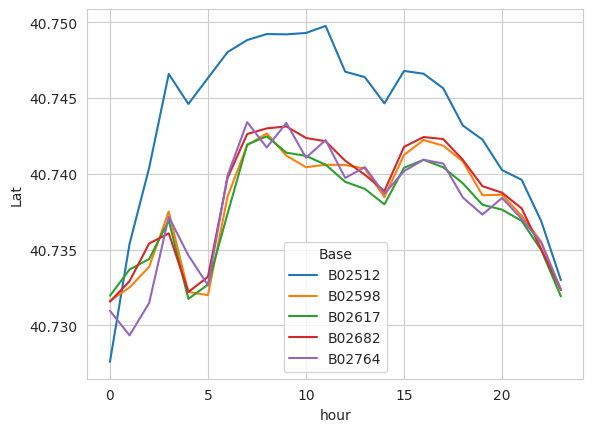

In [ ]:
sns.lineplot(x = "hour", y = "Lat", hue = "Base", data = df, errorbar=None)

<Axes: xlabel='Base', ylabel='count'>

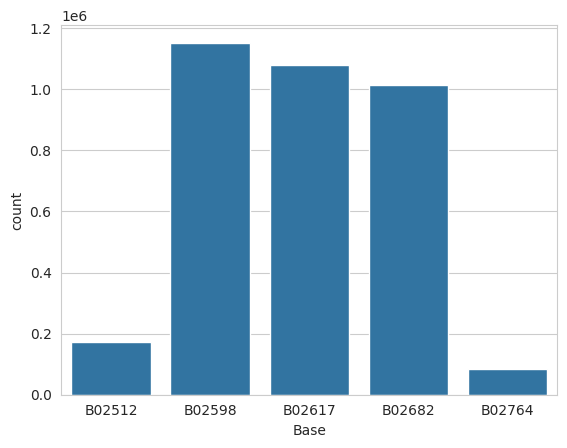

In [ ]:
sns.countplot(data = df, x = "Base")

### E. Dispatch Base Performance & Geographic Coverage
Comparing hourly latitude profiles and total trip counts across Uber's five NYC dispatch bases (`B02512`, `B02598`, `B02617`, `B02682`, `B02764`) revealed clear operational specialization:
* **Core High-Volume Bases:** Bases **B02598**, **B02617**, and **B02682** handled the vast majority of NYC ridership (each exceeding **1.0 million trips** across the five-month window), serving as the primary backbone for citywide demand.
* **Northern Zone Specialization (`B02512`):** While handling a smaller total share of trips, Base **B02512** consistently operated at significantly higher latitudes (**~40.746–40.750** during daytime hours), reflecting dedicated fleet coverage in Upper/Midtown Manhattan.

---

## Strategic Business & Fleet Recommendations
* **Dynamic Rush-Hour Fleet Positioning (14:00 – 23:00 & Thu–Fri):** Increase active driver incentives and surge readiness on **Thursdays and Fridays** between **2:00 PM and 11:00 PM**, when trip demand hits peak weekly and hourly thresholds.
* **Geo-Targeted Shift Allocation (Midtown vs. Downtown):** Reallocate driver supply toward **Midtown Manhattan** (`Lat > 40.742`) during weekday office hours (07:00–18:00), and shift fleet positioning southward toward **Lower Manhattan and Brooklyn** (`Lat < 40.735`) after 22:00 and on weekends.
* **Capacity Scaling for Seasonal Growth:** Given the **~47% surge** in monthly volume between April and August, proactively onboard drivers and expand dispatch capacity across core bases (**B02598**, **B02617**, **B02682**) ahead of late-summer peak demand.